# Walkthrough — data, the 71 features, and why `mean_surprisal`

1. **What the data looks like** — one real paragraph through all three sheets (absolute, cumulative, step), and how the A/B shuffle works.
2. **112 → 71 features** — the three filters, step by step.
3. **Why `mean_surprisal`** — the plots behind the choice.
4. **Where we are now** — all models side by side.

The small example CSVs are saved to `data/paragraph/walkthrough/`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paragraph_dir = Path("../../data/paragraph/master")  # master sheets + feature-engineering/
results_dir = Path("../../output/paragraph/tables")  # experiment result tables
demo_dir = Path("../../data/paragraph/walkthrough")
demo_dir.mkdir(parents=True, exist_ok=True)

SEED = 42
RED, GREY, BLUE = "#d62728", "#b0b0b0", "#1f77b4"
pd.set_option("display.max_colwidth", 70)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. What the data looks like

One paragraph from the article `00s-Music-Quiz` was edited twice:

| version | text |
|---|---|
| v0 | For more information about... |
| v1 | For more information about 2000’s music, check out these resources. |
| v2 | For more information about 2000s music, check out these resources. |

The same three versions are written into three sheets. Only 3 of the 71 features are shown here so the tables stay readable.

In [2]:
ARTICLE, GROUP = "00s-Music-Quiz", 1
SHOW = ["ttr", "mean_mdl", "mean_surprisal"]  # 3 of the 71 features

def example_rows(file):
    df = pd.read_csv(paragraph_dir / file, nrows=50)  # this article is the first one in every sheet
    return df[(df["article"] == ARTICLE) & (df["revision_group_no"] == GROUP)]

### 1a. Absolute sheet — one row per paragraph

Every consecutive step pair ⟨older, newer⟩ becomes **two rows**: older → `base`, newer → `edit`.
v1 shows up twice, once as `edit` (pair 0→1) and once as `base` (pair 1→2), with the *same text but opposite labels*.
That is why we score the absolute sheet **per pair**: correct only when `score(edit) > score(base)`.

In [3]:
absolute = example_rows("master-absolute.csv")[
    ["revision_depth", "pair_older_depth", "pair_newer_depth", "label", "text", *SHOW]
]
absolute.to_csv(demo_dir / "dummy-absolute.csv", index=False)
absolute

,revision_depth,pair_older_depth,pair_newer_depth,label,text,ttr,mean_mdl,mean_surprisal
0,0,0,1,base,For more information about...,0.50000,1.33333,6.49202
1,1,0,1,edit,"For more information about 2000’s music, check out these resources.",0.36207,2.20000,6.91522
2,1,1,2,base,"For more information about 2000’s music, check out these resources.",0.36207,2.20000,6.91522
3,2,1,2,edit,"For more information about 2000s music, check out these resources.",0.35088,2.00000,5.02561


### 1b. Cumulative and step sheets — one row per pair, with `delta = edit − base`

- **cumulative**: every edit against the **original** v0 → pairs (v0, v1) and (v0, v2)
- **step**: every edit against the **previous** version → pairs (v0, v1) and (v1, v2)

Depth 1 is the same pair in both sheets. The `delta_*` columns are what the pair models use.

In [4]:
def pair_view(file):
    df = example_rows(file)
    cols = ["base_depth", "edit_depth", "base_text", "edit_text"]
    for f in SHOW:
        cols += [f"base_{f}", f"edit_{f}", f"delta_{f}"]
    return df[cols]

cumulative = pair_view("master-pairs-cumulative.csv")
step = pair_view("master-pairs-step.csv")
cumulative.to_csv(demo_dir / "dummy-cumulative.csv", index=False)
step.to_csv(demo_dir / "dummy-step.csv", index=False)

print("CUMULATIVE (base is always v0)")
display(cumulative)
print("STEP (base is the previous version)")
display(step)

CUMULATIVE (base is always v0)


,base_depth,edit_depth,base_text,edit_text,base_ttr,edit_ttr,delta_ttr,base_mean_mdl,edit_mean_mdl,delta_mean_mdl,base_mean_surprisal,edit_mean_surprisal,delta_mean_surprisal
0,0,1,For more information about...,"For more information about 2000’s music, check out these resources.",0.5,0.36207,-0.13793,1.33333,2.2,0.86667,6.49202,6.91522,0.42320
1,0,2,For more information about...,"For more information about 2000s music, check out these resources.",0.5,0.35088,-0.14912,1.33333,2.0,0.66667,6.49202,5.02561,-1.46641


STEP (base is the previous version)


,base_depth,edit_depth,base_text,edit_text,base_ttr,edit_ttr,delta_ttr,base_mean_mdl,edit_mean_mdl,delta_mean_mdl,base_mean_surprisal,edit_mean_surprisal,delta_mean_surprisal
0,0,1,For more information about...,"For more information about 2000’s music, check out these resources.",0.50000,0.36207,-0.13793,1.33333,2.2,0.86667,6.49202,6.91522,0.42320
1,1,2,"For more information about 2000’s music, check out these resources.","For more information about 2000s music, check out these resources.",0.36207,0.35088,-0.01119,2.20000,2.0,-0.20000,6.91522,5.02561,-1.88961


### 1c. The shuffle

If the edit were always on the right, the model would just learn "right side = edit".
So each pair is shown as **(A, B) in random order**, and the label is **"is B the edit?"**

- `swap = False` → A = base, B = edit → label **1**, delta kept as `edit − base`
- `swap = True` → A = edit, B = base → label **0**, delta flipped to `base − edit`

So the model always sees `B − A`. The swap uses the same seed and the same rule as Exp 3, over the whole file. Here are the first 6 pairs:

In [5]:
pairs = pd.read_csv(paragraph_dir / "master-pairs-cumulative.csv",
                    usecols=["article", "base_text", "edit_text", "delta_mean_surprisal"])
swap = np.random.default_rng(SEED).integers(0, 2, size=len(pairs)).astype(bool)  # same as exp-3

shuffle = pairs.head(6).copy()
s = swap[:6]
shuffle["swap"] = s
shuffle["A"] = np.where(s, shuffle["edit_text"], shuffle["base_text"])
shuffle["B"] = np.where(s, shuffle["base_text"], shuffle["edit_text"])
shuffle["label (B is edit)"] = (~s).astype(int)
shuffle["delta_mean_surprisal (edit-base)"] = shuffle.pop("delta_mean_surprisal")
shuffle["model sees (B-A)"] = shuffle["delta_mean_surprisal (edit-base)"] * np.where(s, -1, 1)
shuffle = shuffle.drop(columns=["article", "base_text", "edit_text"])
shuffle.to_csv(demo_dir / "dummy-shuffle.csv", index=False)
print(f"whole file: {swap.mean():.1%} of pairs swapped -> labels are balanced")
shuffle

whole file: 50.1% of pairs swapped -> labels are balanced


,swap,A,B,label (B is edit),delta_mean_surprisal (edit-base),model sees (B-A)
0,False,For more information about...,"For more information about 2000’s music, check out these resources.",1,0.42320,0.42320
1,True,"For more information about 2000s music, check out these resources.",For more information about...,0,-1.46641,1.46641
2,True,"Just answer these fun trivia questions, and we’ll let you know if ...","Just answer these fun trivia questions, and we’ll let you know if ...",0,0.14681,-0.14681
3,False,Do you consider yourself a 2000’s music expert? Can you belt out s...,Do you consider yourself a 2000s music expert? Can you belt out so...,1,-0.01388,-0.01388
4,False,Beyoncé and Rihanna are tied for the second most #1 entries on the...,Beyoncé and Rihanna are tied for the second - most #1 entries on t...,1,0.67269,0.67269
5,True,"Usher had 7 number - one hits on the Billboard Hot 100 chart, the ...","Usher had 7 number one hits on the Billboard Hot 100 chart, the mo...",0,0.56119,-0.56119


## 2. From 112 features to 71

Everything numeric in `master-absolute.csv`, except id columns, is a candidate (**112**). Four filters, in order:

0. **Undefined** — features where 0 means "could not be calculated" in more than 5% of rows (`vocd`, `word_vocd`); one-word paragraphs are left out.
1. **Constant** — same value in every row, so it can't help.
2. **Highly correlated (|r| > 0.90)** — keep one from each pair. `mean_mdl` is preferred when it is in a pair.
3. **Surprisal keep-one** — 3 surprisal columns survive step 2 (GPT-2 + 2 n-gram). Only GPT-2 `mean_surprisal` is kept; section 3 shows why.

This repeats `code/3-dataset-building/feature-engineering.ipynb` and checks that the result matches `final_features.csv`.

In [6]:
SKIP = {"article", "revision_group_no", "revision_depth", "pair_older_depth", "pair_newer_depth", "label", "text"}
raw_df = pd.read_csv(paragraph_dir / "master-absolute.csv", low_memory=False)
num_df = raw_df.drop(columns=[c for c in raw_df.columns if c in SKIP]).select_dtypes(include="number")

initial = list(num_df.columns)
active = list(initial)
funnel = [("all features", len(active), [])]

# 0) undefined values - same rule as feature-engineering.ipynb: 0 means "could not be calculated" for these features
UNDEFINED_WHEN_ZERO = ["mean_mdl", "mean_surprisal", "ttr", "msttr", "mattr", "mtld", "mtld_ma", "vocd",
                       "word_ttr", "word_msttr", "word_mattr", "word_mtld", "word_mtld_ma", "word_vocd"]
undefined = pd.DataFrame({c: num_df[c] == 0 for c in UNDEFINED_WHEN_ZERO if c in active})
undefined_share = undefined.mean()
drop_undefined = sorted(undefined_share[undefined_share > 0.05].index) #undefined in more than 5% of rows
active = [c for c in active if c not in drop_undefined]
funnel.append(("drop undefined (> 5% rows)", len(active), drop_undefined))
row_undefined = undefined.drop(columns=drop_undefined).any(axis=1) #one word paragraphs - left out of the next steps
num_df = num_df[~row_undefined]

# 1) constant
constant = [c for c in active if num_df[c].nunique() == 1]
active = [c for c in active if c not in constant]
funnel.append(("drop constant", len(active), constant))

# 2) correlation > 0.90 (prefer to keep mean_mdl)
corr = num_df[active].corr().abs()
drop_corr = set()
for i, a in enumerate(active):
    for b in active[i + 1:]:
        if pd.isna(corr.at[a, b]) or corr.at[a, b] <= 0.90:
            continue
        drop_corr.add(a if b == "mean_mdl" else b)
active = [c for c in active if c not in drop_corr]
funnel.append(("drop |r| > 0.90", len(active), sorted(drop_corr)))

# 3) surprisal keep-one: keep GPT-2 mean_surprisal (see section 3)
surprisal_left = [c for c in active if c.startswith("mean_surprisal")]
drop_surprisal = [c for c in surprisal_left if c != "mean_surprisal"]
active = [c for c in active if c not in drop_surprisal]
funnel.append(("keep 1 surprisal", len(active), drop_surprisal))

final = pd.read_csv(paragraph_dir / "feature-engineering" / "final_features.csv")["feature"].tolist()
print("matches final_features.csv:", set(active) == set(final), f"({len(final)} features)")

pd.DataFrame([{"step": s, "remaining": n, "removed": len(r), "removed features": ", ".join(r)}
              for s, n, r in funnel])

matches final_features.csv: True (71 features)


,step,remaining,removed,removed features
0,all features,112,0,
1,drop undefined (> 5% rows),110,2,"vocd, word_vocd"
2,drop constant,98,12,"dep_acl_relcl, dep_aux_pass, dep_cop, dep_discourse, dep_fixed, de..."
3,drop |r| > 0.90,73,25,"avg_sen_len, depbig_NOUN_DET_before, mattr, mean_surprisal_brown_2..."
4,keep 1 surprisal,71,2,"mean_surprisal_brown_1, mean_surprisal_wikitext2_2"


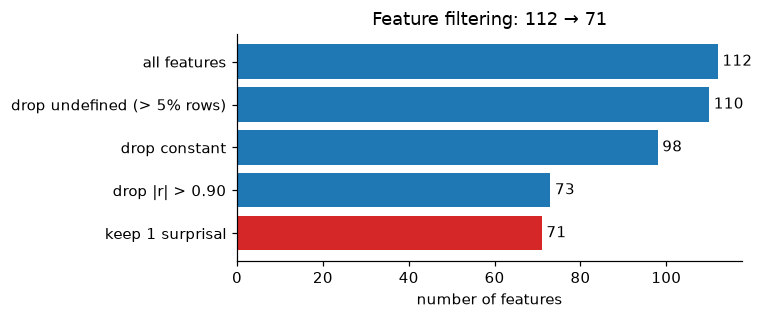

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
names = [s for s, _, _ in funnel]
counts = [n for _, n, _ in funnel]
bars = ax.barh(names[::-1], counts[::-1], color=[RED] + [BLUE] * (len(counts) - 1))
ax.bar_label(bars, padding=3)
ax.set_xlabel("number of features")
ax.set_title(f"Feature filtering: {counts[0]} → {counts[-1]}")
plt.tight_layout()
plt.show()

## 3. Why `mean_surprisal` (GPT-2)

We had **21 surprisal columns**: GPT-2 (`mean_surprisal`) plus SRILM n-gram models
(orders 1–5 × Brown, WikiText-2, PTB-WSJ, SimpleWiki). The plots below show why only GPT-2 is kept.

### 3a. The n-gram surprisals mostly repeat each other; GPT-2 does not

Correlation between the 21 columns (absolute rows). The n-gram columns form one block with high correlation.
GPT-2 correlates only weakly with them, so it carries **different information**.

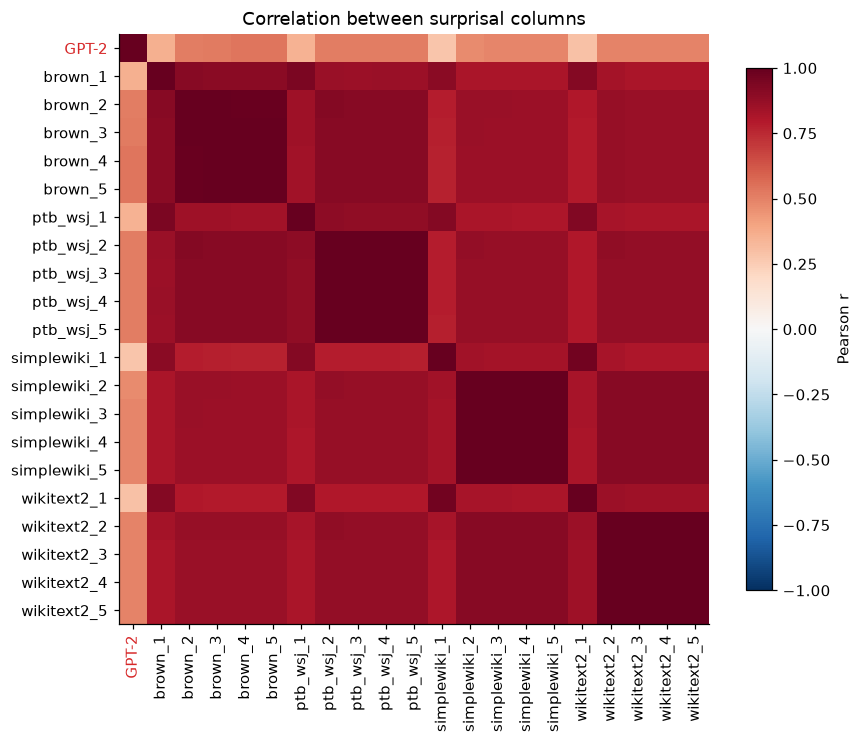

mean |r| of GPT-2 with the 20 n-gram columns: 0.467
mean |r| among the 20 n-gram columns:        0.88


In [8]:
surprisal_cols = ["mean_surprisal"] + sorted(
    c for c in num_df.columns if c.startswith("mean_surprisal_"))
short = ["GPT-2"] + [c.replace("mean_surprisal_", "") for c in surprisal_cols[1:]]
r = num_df[surprisal_cols].corr().to_numpy()

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(r, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(short)), short, rotation=90)
ax.set_yticks(range(len(short)), short)
ax.get_xticklabels()[0].set_color(RED)
ax.get_yticklabels()[0].set_color(RED)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation between surprisal columns")
plt.tight_layout()
plt.show()

print("mean |r| of GPT-2 with the 20 n-gram columns:", np.abs(r[0, 1:]).mean().round(3))
print("mean |r| among the 20 n-gram columns:       ",
      np.abs(r[1:, 1:][np.triu_indices(20, 1)]).mean().round(3))

### 3b. Exp 1: adding GPT-2 surprisal to TF-IDF gives by far the largest gain

Accuracy gain over `tfidf_only` when **one** surprisal column is added to TF-IDF (`exp1-tfidf-surprisal.csv`).
On both pair sheets GPT-2 is far ahead of every n-gram model.

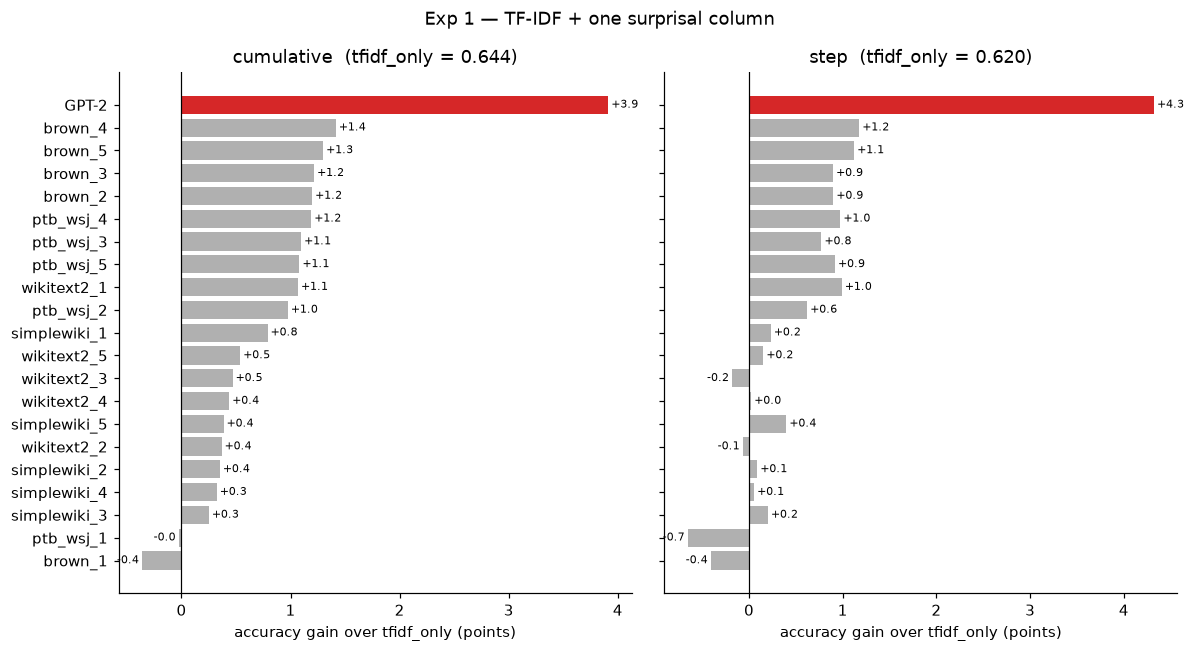

In [9]:
exp1 = pd.read_csv(results_dir / "exp1-tfidf-surprisal.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
for ax, file in zip(axes, ["cumulative", "step"]):
    part = exp1[exp1["file"] == file].set_index("surprisal")["accuracy"]
    gain = (part.drop("tfidf_only") - part["tfidf_only"]).sort_values() * 100
    labels = ["GPT-2" if n == "mean_surprisal" else n.replace("mean_surprisal_", "") for n in gain.index]
    bars = ax.barh(labels, gain.values, color=[RED if n == "mean_surprisal" else GREY for n in gain.index])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{file}  (tfidf_only = {part['tfidf_only']:.3f})")
    ax.set_xlabel("accuracy gain over tfidf_only (points)")
axes[0].bar_label(axes[0].containers[0], fmt="%+.1f", padding=2, fontsize=7)
axes[1].bar_label(axes[1].containers[0], fmt="%+.1f", padding=2, fontsize=7)
fig.suptitle("Exp 1 — TF-IDF + one surprisal column")
plt.tight_layout()
plt.show()

### 3c. Exp 2: MDL adds nothing on top of surprisal

`exp2-tfidf-surprisal-mdl.csv`: TF-IDF alone, + MDL, + surprisal, + both.

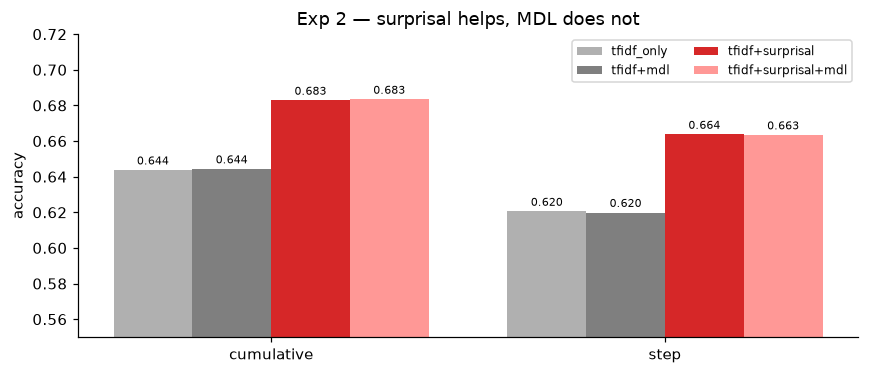

In [10]:
exp2 = pd.read_csv(results_dir / "exp2-tfidf-surprisal-mdl.csv")
sets = ["tfidf_only", "tfidf+mdl", "tfidf+surprisal", "tfidf+surprisal+mdl"]
files = ["cumulative", "step"]

fig, ax = plt.subplots(figsize=(8, 3.5))
width = 0.2
for i, fs in enumerate(sets):
    vals = [exp2[(exp2["file"] == f) & (exp2["feature_set"] == fs)]["accuracy"].iloc[0] for f in files]
    color = RED if fs == "tfidf+surprisal" else [GREY, "#7f7f7f", RED, "#ff9896"][i]
    bars = ax.bar(np.arange(len(files)) + (i - 1.5) * width, vals, width, label=fs, color=color)
    ax.bar_label(bars, fmt="%.3f", fontsize=7, padding=2)
ax.set_xticks(range(len(files)), files)
ax.set_ylim(0.55, 0.72)
ax.set_ylabel("accuracy")
ax.legend(fontsize=8, ncol=2)
ax.set_title("Exp 2 — surprisal helps, MDL does not")
plt.tight_layout()
plt.show()

### 3d. The intuition: edits tend to make text more predictable

`delta_mean_surprisal = edit − base` over all cumulative pairs. Most of the mass is **below 0**:
after editing, GPT-2 usually finds the paragraph *less surprising*.

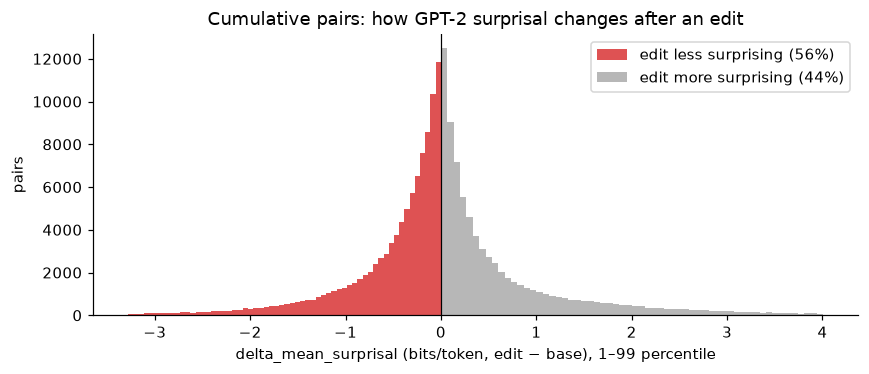

median delta: -0.0534


In [11]:
delta = pd.read_csv(paragraph_dir / "master-pairs-cumulative.csv", usecols=["delta_mean_surprisal"])["delta_mean_surprisal"].dropna()
lo, hi = delta.quantile([0.01, 0.99])
clipped = delta[(delta >= lo) & (delta <= hi)]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(clipped[clipped < 0], bins=60, color=RED, alpha=0.8, label=f"edit less surprising ({(delta < 0).mean():.0%})")
ax.hist(clipped[clipped > 0], bins=60, color=GREY, alpha=0.9, label=f"edit more surprising ({(delta > 0).mean():.0%})")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("delta_mean_surprisal (bits/token, edit − base), 1–99 percentile")
ax.set_ylabel("pairs")
ax.legend()
ax.set_title("Cumulative pairs: how GPT-2 surprisal changes after an edit")
plt.tight_layout()
plt.show()
print("median delta:", round(delta.median(), 4))

### 3e. Exp 3: among all 71 features, `mean_surprisal` is still one of the strongest

Weights of the 71 (scaled) features in the `tfidf+all_features` model (`exp3-feature-weights.csv`), averaged over cumulative and step.
Negative = pushes towards **base**, so a higher surprisal points to the older version.

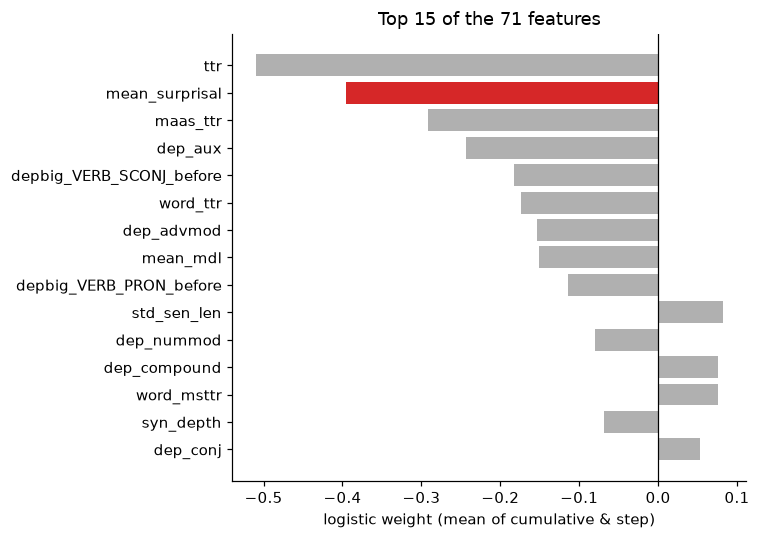

In [12]:
weights = pd.read_csv(results_dir / "exp3-feature-weights.csv", index_col=0)
top = weights.head(15)
avg = top[["cumulative", "step"]].mean(axis=1)[::-1]

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(avg.index, avg.values, color=[RED if n == "mean_surprisal" else GREY for n in avg.index])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("logistic weight (mean of cumulative & step)")
ax.set_title("Top 15 of the 71 features")
plt.tight_layout()
plt.show()

## 4. Where we are now

Accuracy on the two pair sheets, across experiments.

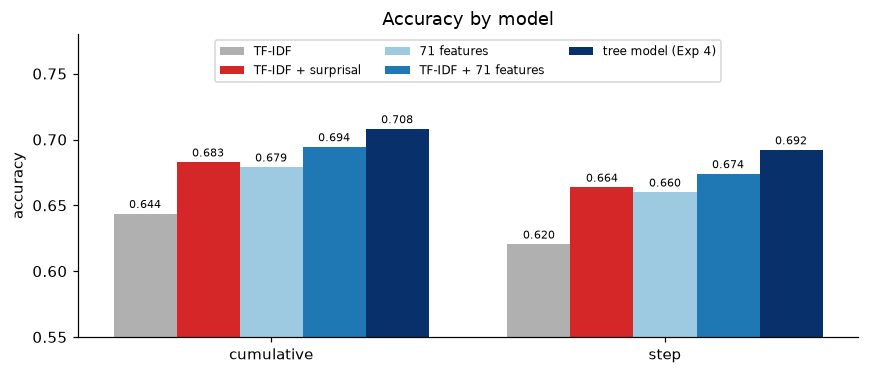

,cumulative,step
TF-IDF,0.6437,0.6205
TF-IDF + surprisal,0.6828,0.6637
71 features,0.6791,0.6600
TF-IDF + 71 features,0.6944,0.6740
tree model (Exp 4),0.7081,0.6921


In [13]:
exp3 = pd.read_csv(results_dir / "exp3-tfidf-all-features.csv")
exp4 = pd.read_csv(results_dir / "exp4-tree-model.csv")

def acc(df, file, col, value):
    row = df[(df["file"] == file) & (df[col] == value)]
    return row["accuracy"].iloc[0] if len(row) else np.nan

models = [
    ("TF-IDF",                    lambda f: acc(exp2, f, "feature_set", "tfidf_only")),
    ("TF-IDF + surprisal",        lambda f: acc(exp2, f, "feature_set", "tfidf+surprisal")),
    ("71 features",               lambda f: acc(exp3, f, "feature_set", "features_only")),
    ("TF-IDF + 71 features",      lambda f: acc(exp3, f, "feature_set", "tfidf+all_features")),
    ("tree model (Exp 4)",        lambda f: acc(exp4, f, "model", "tree")),
]
summary = pd.DataFrame({f: [fn(f) for _, fn in models] for f in files}, index=[m for m, _ in models])

fig, ax = plt.subplots(figsize=(8, 3.5))
width = 0.16
palette = [GREY, RED, "#9ecae1", BLUE, "#08306b"]
for i, (name, row) in enumerate(summary.iterrows()):
    bars = ax.bar(np.arange(len(files)) + (i - 2) * width, row.values, width, label=name, color=palette[i])
    ax.bar_label(bars, fmt="%.3f", fontsize=7, padding=2)
ax.set_xticks(range(len(files)), files)
ax.set_ylim(0.55, 0.78)
ax.set_ylabel("accuracy")
ax.legend(fontsize=8, ncol=3, loc="upper center")
ax.set_title("Accuracy by model")
plt.tight_layout()
plt.show()
summary.round(4)